# 13. Анализ прогнозируемости

Рабочий ноутбук к главе книги `../chapters/13-predictability.md`: здесь только задания и код, теория и выводы — в главе. Источник — глава 30 пособия.

Все задания — на синтетике. Нужен предобученный анализатор `../local/models/weasel_D.pickle` — как скачать, написано в `../README.md`.

Графики для главы сохраняй через `save_fig(fig, "имя")` → `../chapters/img/13-имя.png`.

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Глушим шум до импорта ETNA: FutureWarning из pandas и предупреждение tqdm про ipywidgets
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
# Модель анализатора сохранена в sklearn 1.0.2 — sklearn предупреждает о другой версии при загрузке
warnings.filterwarnings("ignore", message="Trying to unpickle estimator")

from etna.datasets import TSDataset
from etna.models import NaiveModel
from etna.pipeline import Pipeline
from etna.metrics import SMAPE
from etna.experimental.classification import PredictabilityAnalyzer

# Предобученный анализатор скачивается отдельно (см. README темы) и в git не попадает
MODEL_PATH = "../local/models/weasel_D.pickle"
IMG_DIR = "../chapters/img"  # графики для главы книги
RANDOM_SEED = 42


def save_fig(fig, name: str) -> None:
    """Сохранить график для главы книги: ../chapters/img/13-<name>.png."""
    os.makedirs(IMG_DIR, exist_ok=True)
    fig.savefig(f"{IMG_DIR}/13-{name}.png", dpi=150, bbox_inches="tight")

## Задание 1. Синтетика: годится ли ряд для прогноза

Набор рядов, про каждый из которых заранее понятно, хороший он или плохой: вердикт анализатора по сырым рядам сравниваем с настоящей ошибкой прогноза.

### Шаг 1.1. Набор рядов

7 рядов по году дневных данных: два хороших (недельный узор, с трендом и без), три плохих (случайное блуждание, скачок уровня в конце, редкие продажи) и два шума — с маленьким и большим разбросом.

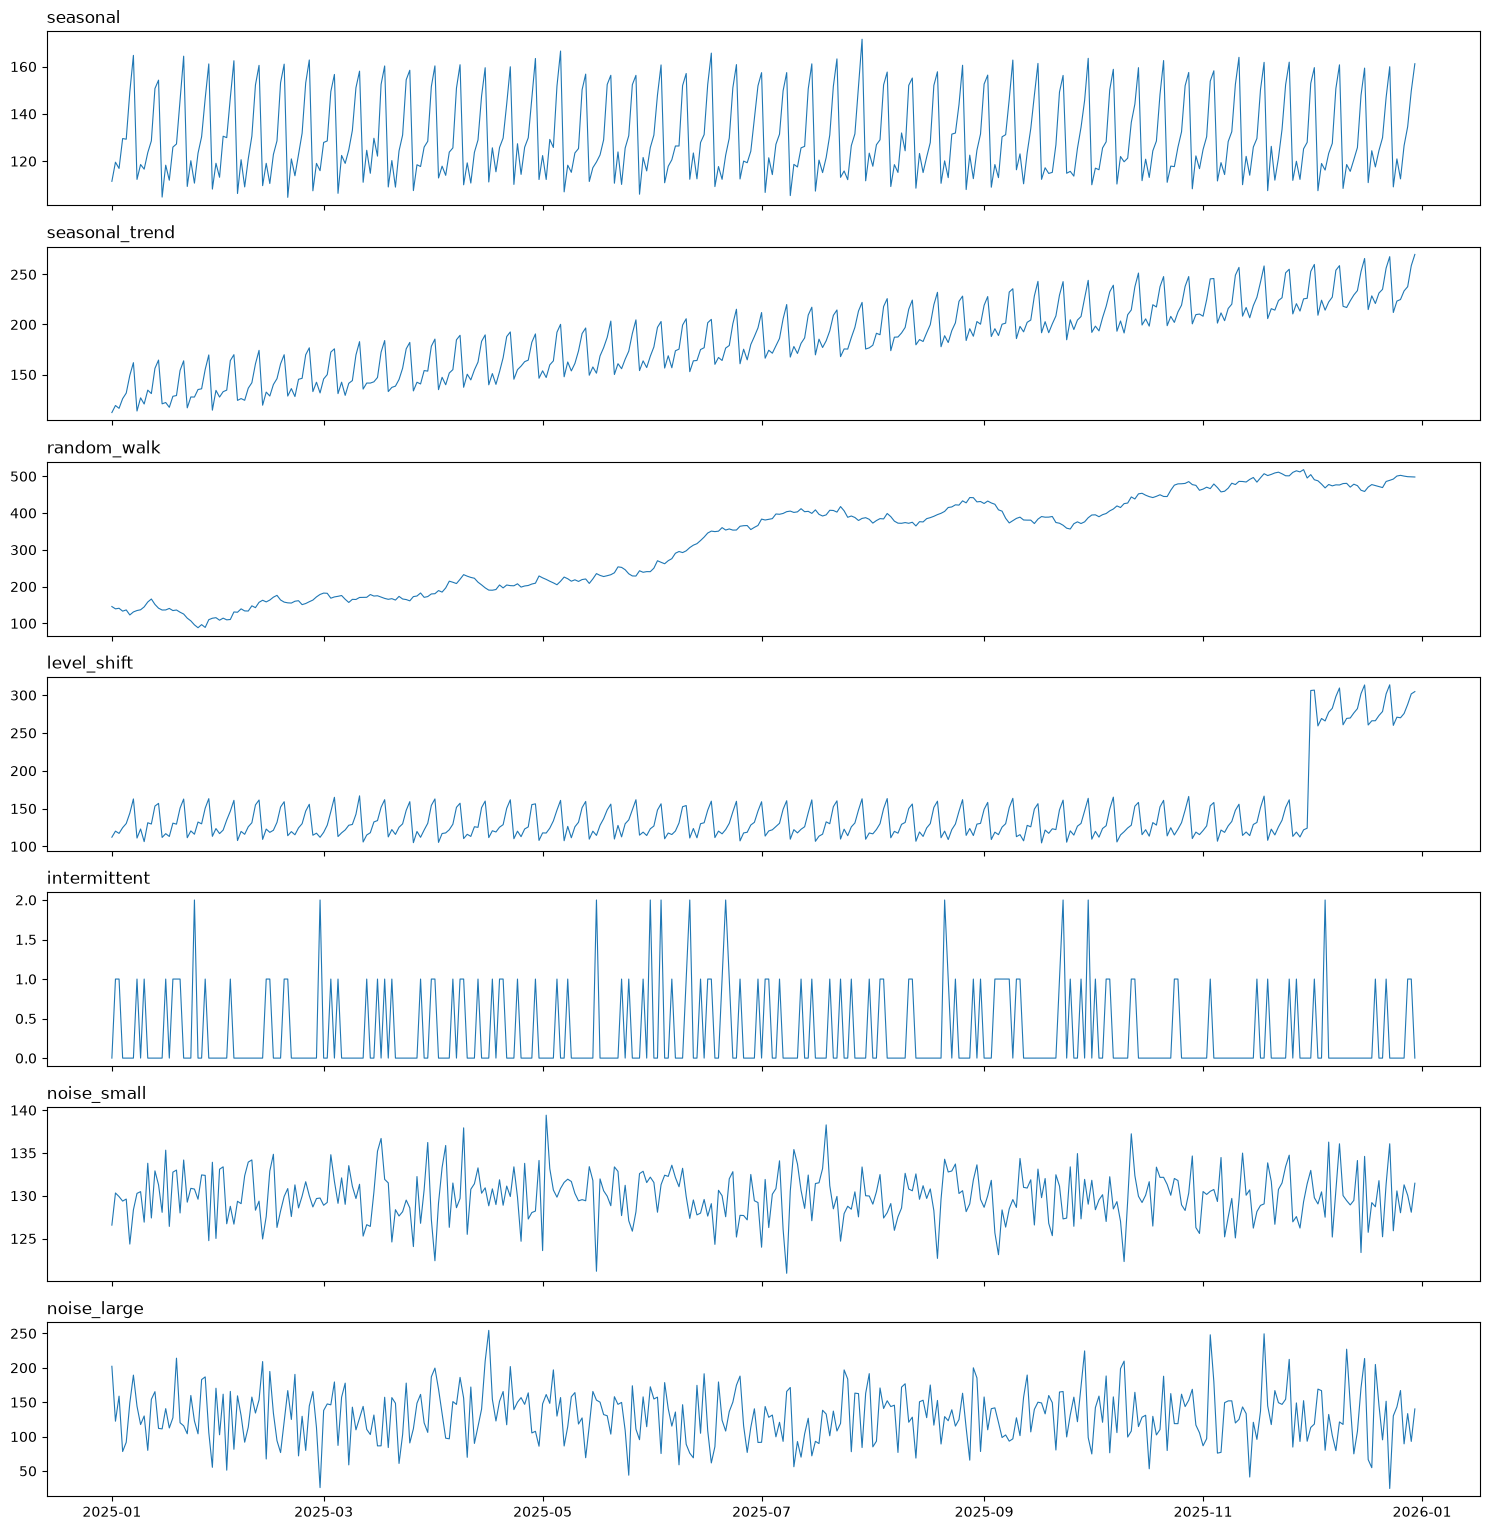

In [2]:
# 7 рядов по году дневных данных, у каждого понятная «судьба»
PERIODS = 52 * 7
DAY_OF_WEEK_PATTERN = np.array([10, 20, 15, 25, 30, 50, 60], dtype=float)
rng = np.random.RandomState(RANDOM_SEED)
t = np.arange(PERIODS)
weekly = np.tile(DAY_OF_WEEK_PATTERN, PERIODS // 7)

SERIES = {
    # хорошие: узор повторяется, шум маленький
    "seasonal": 100 + weekly + rng.normal(0, 3, PERIODS),
    "seasonal_trend": 100 + 0.3 * t + weekly + rng.normal(0, 3, PERIODS),
    # плохие: будущее не следует из прошлого
    "random_walk": 150 + np.cumsum(rng.normal(0, 8, PERIODS)),
    "level_shift": 100 + weekly + rng.normal(0, 3, PERIODS) + np.where(t >= PERIODS - 30, 150, 0),
    "intermittent": rng.poisson(0.3, PERIODS).astype(float),
    # шум: узора нет, но разброс маленький относительно уровня
    "noise_small": 130 + rng.normal(0, 3, PERIODS),
    "noise_large": 130 + rng.normal(0, 40, PERIODS),
}
timestamps = pd.date_range("2025-01-01", periods=PERIODS, freq="D")
df = pd.concat(
    [pd.DataFrame({"timestamp": timestamps, "segment": name, "target": values}) for name, values in SERIES.items()]
)
ts = TSDataset(df, freq="D")

fig, axes = plt.subplots(len(SERIES), 1, figsize=(15, 2.2 * len(SERIES)), sharex=True)
for ax, name in zip(axes, SERIES):
    ax.plot(timestamps, SERIES[name], linewidth=0.8)
    ax.set_title(name, loc="left")
fig.tight_layout()
save_fig(fig, "series")

#### Выводы

- **7 рядов по году дневных данных**, у каждого заранее понятная судьба:
  - **хорошие** — `seasonal` (недельный узор + шум ±3) и `seasonal_trend` (то же плюс рост);
  - **плохие** — `random_walk` (случайное блуждание), `level_shift` (за 30 дней до конца уровень прыгает на +150), `intermittent` (редкие продажи: в основном нули);
  - **шум без узора** — `noise_small` (разброс ±3 вокруг 130) и `noise_large` (разброс ±40).

### Шаг 1.2. Вердикт анализатора

`PredictabilityAnalyzer` (WEASEL, дневная частота): `analyze_predictability` даёт вердикт 0/1, `predict_proba` — вероятность, что ряд плохой. Никакой обработки рядов до анализа.

In [3]:
# Вердикт анализатора по сырым рядам: 1 — ряд плохо прогнозируется, 0 — хорошо
analyzer = PredictabilityAnalyzer.load(MODEL_PATH)

start = time.perf_counter()
verdict = analyzer.analyze_predictability(ts)
analyzer_seconds = time.perf_counter() - start

# Вероятность класса 1 («плохой»); ряды в get_series_from_dataset идут в алфавитном порядке сегментов
proba_bad = analyzer.predict_proba(analyzer.get_series_from_dataset(ts))

result = pd.DataFrame({"analyzer_verdict": verdict, "proba_bad": dict(zip(sorted(ts.segments), proba_bad))})
print(f"анализатор: {analyzer_seconds:.1f} с на {len(ts.segments)} рядов")
result.round(2)

анализатор: 1.7 с на 7 рядов


,analyzer_verdict,proba_bad
intermittent,0,0.43
level_shift,0,0.24
noise_large,1,0.52
noise_small,0,0.47
random_walk,0,0.40
seasonal,0,0.28
seasonal_trend,0,0.08


#### Выводы

| ряд | вердикт (1 — плохой) | вероятность «плохой» |
|---|---|---|
| `seasonal_trend` | 0 | 0.08 |
| `level_shift` | 0 | 0.24 |
| `seasonal` | 0 | 0.28 |
| `random_walk` | 0 | 0.40 |
| `intermittent` | 0 | 0.43 |
| `noise_small` | 0 | 0.47 |
| `noise_large` | **1** | 0.52 |

- **Анализатор отработал за 1.7 секунды** по сырым рядам — без обработки и без модели прогноза.
- **С порогом по умолчанию (0.5) плохим признан только `noise_large`.** Остальные ряды прошли, хотя вероятности сильно разные: от 0.08 у ряда с трендом и узором до 0.47 у шума.
- **Шумы почти не различаются:** 0.47 и 0.52, хотя разброс у них отличается в 13 раз. Анализатор смотрит на форму ряда, а не на его масштаб.

### Шаг 1.3. Проверка прогнозом

Backtest `NaiveModel(lag=7)`: горизонт 14 дней, 3 фолда, SMAPE. Ряд плохой, если SMAPE ≥ 20%. Совпал ли вердикт анализатора с настоящей ошибкой.

In [4]:
# Честная проверка: backtest простой модели «как в тот же день неделю назад», горизонт 14 дней, 3 фолда
pipeline = Pipeline(model=NaiveModel(lag=7), transforms=[], horizon=14)
metrics_df = pipeline.backtest(ts, metrics=[SMAPE()], n_folds=3, aggregate_metrics=True, joblib_params={"verbose": 0})["metrics"]

SMAPE_THRESHOLD = 20  # ряд считаем плохим, если ошибка простой модели не меньше 20%
result["smape"] = metrics_df.set_index("segment")["SMAPE"]
result["smape_verdict"] = (result["smape"] >= SMAPE_THRESHOLD).astype(int)
result["match"] = result["analyzer_verdict"] == result["smape_verdict"]
result.round(2)

,analyzer_verdict,proba_bad,smape,smape_verdict,match
intermittent,0,0.43,71.43,1,False
level_shift,0,0.24,22.96,1,False
noise_large,1,0.52,38.05,1,True
noise_small,0,0.47,2.74,0,True
random_walk,0,0.40,4.63,0,True
seasonal,0,0.28,2.13,0,True
seasonal_trend,0,0.08,1.79,0,True


#### Выводы

| ряд | вердикт анализатора | SMAPE, % | вердикт по SMAPE ≥ 20 | совпали |
|---|---|---|---|---|
| `seasonal_trend` | 0 | 1.8 | 0 | да |
| `seasonal` | 0 | 2.1 | 0 | да |
| `noise_small` | 0 | 2.7 | 0 | да |
| `random_walk` | 0 | 4.6 | 0 | да |
| `level_shift` | 0 | 23.0 | 1 | **нет** |
| `noise_large` | 1 | 38.1 | 1 | да |
| `intermittent` | 0 | 71.4 | 1 | **нет** |

- **Совпало 5 из 7.** Хорошие ряды и сильный шум анализатор оценил верно.
- **`intermittent` анализатор ошибочно признал хорошим (0),** хотя ошибка прогноза самая большая — 71%. Вероятность «плохой» 0.43 — ниже порога 0.5, но близко к нему.
- **`level_shift` тоже признан хорошим, причём уверенно (вероятность «плохой» 0.24):** почти весь год ряд выглядит как хороший недельный узор, а скачок случился только в конце. Анализатор оценивает историю целиком и разовую поломку в конце не замечает.
- **`random_walk` и `noise_small` по SMAPE хорошие:** простая модель ошибается всего на 3–5%, потому что шаги ряда маленькие относительно его уровня.

### Шаг 1.4. Порог

Как меняется список плохих рядов, если снижать порог вероятности: 0.5 (по умолчанию), 0.4, 0.3, 0.2.

In [5]:
# Порог вероятности: по умолчанию 0.5; ниже порог — больше рядов попадает в «плохие»
thresholds = [0.5, 0.4, 0.3, 0.2]
pd.DataFrame(
    {f"threshold_{threshold}": (result["proba_bad"] > threshold).astype(int) for threshold in thresholds}
).assign(proba_bad=result["proba_bad"].round(2), smape_verdict=result["smape_verdict"])

,threshold_0.5,threshold_0.4,threshold_0.3,threshold_0.2,proba_bad,smape_verdict
intermittent,0,1,1,1,0.43,1
level_shift,0,0,0,1,0.24,1
noise_large,1,1,1,1,0.52,1
noise_small,0,1,1,1,0.47,0
random_walk,0,0,1,1,0.40,0
seasonal,0,0,0,1,0.28,0
seasonal_trend,0,0,0,0,0.08,0


#### Выводы

| порог | плохими признаны | совпало с SMAPE из 7 |
|---|---|---|
| 0.5 (по умолчанию) | `noise_large` | 5 |
| 0.4 | + `intermittent`, `noise_small` | 5 |
| 0.3 | + `random_walk` | 4 |
| 0.2 | + `level_shift`, `seasonal` | 4 |

- **Снижение порога не помогает:** вместе с настоящим плохим `intermittent` в список попадает `noise_small`, у которого SMAPE 2.7%. Чем ниже порог, тем больше ложных тревог.
- **`level_shift` попадает в плохие только при пороге 0.2** — вместе с хорошим `seasonal`.
- **Вероятность полезнее вердикта:** по ней ряды можно отсортировать от «скорее хороших» к «скорее плохим», а смотреть глазами начать с верха списка.